# Regularization


The objective is to learn how to use regularization in deep learning models in order to prevent/ovoid overfitting.

Let's first import the packages you are going to use.

In [1]:
# import packages
import numpy as np

# Compatibility with old reg_utils.py
if not hasattr(np, "int"):
    np.int = int
    
import matplotlib.pyplot as plt
from reg_utils import sigmoid, relu, plot_decision_boundary, initialize_parameters, load_2D_dataset, predict_dec
from reg_utils import compute_cost, predict, forward_propagation, backward_propagation, update_parameters
import sklearn
import sklearn.datasets
import scipy.io
#from testCases import *

%matplotlib inline
plt.rcParams['figure.figsize'] = (7.0, 4.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

**Problem Statement**: We have to classify a 2D data points into 2 classes.


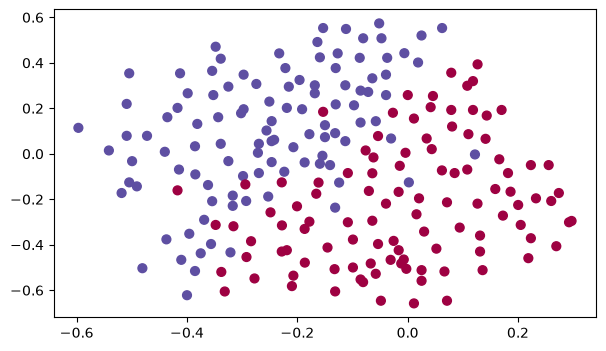

In [2]:
data = scipy.io.loadmat('data.mat')
train_X = data['X'].T
train_Y = data['y'].T
test_X = data['Xval'].T
test_Y = data['yval'].T

plt.scatter(train_X[0, :], train_X[1, :], c=train_Y, s=40, cmap=plt.cm.Spectral);

**The objective**: Correctly classify the 2D points.

**Analysis of the dataset**: This dataset is a little bit noisy, but it looks like a diagonal line separating the blue points from the red ones.

**Steps**

- First, try a non-regularized model.
- Second, try different regularized models.
- Analyze the results and choose the best models.


## 1 - Baseline model -- Non-regularized

Use the following neural network. This model can be used:
- in *regularization mode* -- by setting the `lambd` input to a non-zero value.
- in *dropout mode* -- by setting the `keep_prob` to a value less than one.

You will first try the model without any regularization. Then, you will implement:
- *L2 regularization* -- functions: "`compute_cost_with_regularization()`" and "`backward_propagation_with_regularization()`"
- *Dropout* -- functions: "`forward_propagation_with_dropout()`" and "`backward_propagation_with_dropout()`"

In each part, you will run this model with the correct inputs so that it calls the right functions.

**First thing to do:** Take a look at the code below to familiarize yourself with the model.

In [3]:
def model(X, Y, learning_rate = 0.3, num_iterations = 30000, print_cost = True, lambd = 0, keep_prob = 1, layers_dims = None):
    """
    Implements a three-layer neural network: LINEAR->RELU->LINEAR->RELU->LINEAR->SIGMOID.

    Arguments:
    X -- input data, of shape (input size, number of examples)
    Y -- true "label" vector (1 for blue dot / 0 for red dot), of shape (output size, number of examples)
    learning_rate -- learning rate of the optimization
    num_iterations -- number of iterations of the optimization loop
    print_cost -- If True, print the cost every 10000 iterations
    lambd -- regularization hyperparameter, scalar
    keep_prob - probability of keeping a neuron active during drop-out, scalar.
    layers_dims -- list containing the dimensions of each layer in our network.

    Returns:
    parameters -- parameters learned by the model. They can then be used to predict.
    """

    grads = {}
    costs = []                            # to keep track of the cost
    m = X.shape[1]                        # number of examples
    if layers_dims is None:
        layers_dims = [X.shape[0], 20, 3, 1]  # A three layer NN:
                                              #      20 neurons in the layer #1
                                              #      3 neurons in the layer #2
                                              #      1 neurons in the layer #3 (the output layer)

    # Initialize parameters dictionary.
    parameters = initialize_parameters(layers_dims)

    # Loop (gradient descent)
    for i in range(0, num_iterations):

        # Forward propagation: LINEAR -> RELU -> LINEAR -> RELU -> LINEAR -> SIGMOID.
        if keep_prob == 1:
            a3, cache = forward_propagation(X, parameters)
        elif keep_prob < 1:
            a3, cache = forward_propagation_with_dropout(X, parameters, keep_prob)

        # Cost function
        if lambd == 0:
            cost = compute_cost(a3, Y)
        else:
            cost = compute_cost_with_regularization(a3, Y, parameters, lambd)

        # Backward propagation.
        assert(lambd==0 or keep_prob==1)    # In practice, it is possible to use both L2 regularization and dropout,
                                            # but this exercise will only explore one at a time
        if lambd == 0 and keep_prob == 1:
            grads = backward_propagation(X, Y, cache)
        elif lambd != 0:
            grads = backward_propagation_with_regularization(X, Y, cache, lambd)
        elif keep_prob < 1:
            grads = backward_propagation_with_dropout(X, Y, cache, keep_prob)

        # Update parameters.
        parameters = update_parameters(parameters, grads, learning_rate)

        # Print the loss every 10000 iterations
        if print_cost and i % 10000 == 0:
            print("Cost after iteration {}: {}".format(i, cost))
        if print_cost and i % 1000 == 0:
            costs.append(cost)

    # plot the cost
    if print_cost and costs:
        plt.plot(costs)
        plt.ylabel('cost')
        plt.xlabel('iterations (x1,000)')
        plt.title("Learning rate =" + str(learning_rate))
        plt.show()

    return parameters

Let's train the model without any regularization, and observe the accuracy on the train/test sets.


# To Do:

Train a model whithout any regularization.
Try to obtain the highest possible accuracy varying hyper-parameters: learning_rate = 0.3, num_iterations = 30000
Do not modify the architecture of the network (defined in layers_dims).


Using the fonction "model" defined here above.

This function return "parameters" that you can use with function "predict" to evaluate the performance of the model.

Examples of Basic calls to these functions are:
- parameters = model(X, Y)
- predictions_train = predict(Xtr, Ytr, parameters)
- predictions_test = predict(Xte, Yte, parameters)


Cost after iteration 0: 0.6557412523481002
Cost after iteration 10000: 0.16329987525724216
Cost after iteration 20000: 0.13851642423254343


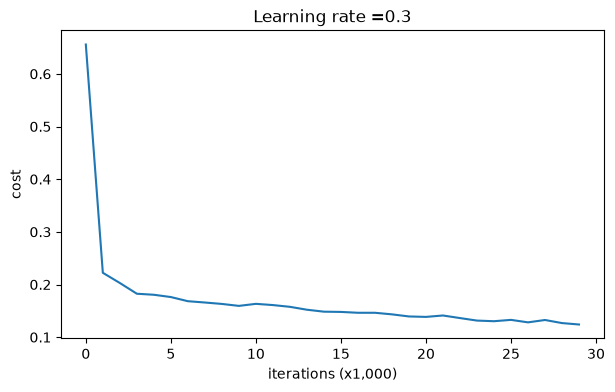

On the training set:
Accuracy: 0.9478672985781991
On the test set:
Accuracy: 0.915


In [4]:
parameters = model(train_X, train_Y)
print ("On the training set:")
predictions_train = predict(train_X, train_Y, parameters)
print ("On the test set:")
predictions_test = predict(test_X, test_Y, parameters)

Provide the report of your experiments here:

- **Train accuracy**: 94.8% (0.948)
- **Test accuracy**: 91.5% (0.915)

The baseline model fits the training set well, but suffers from overfitting (high variance). Because the model is complex enough to memorize noise and outliers in the training data, its test accuracy drops to 91.5%.

### Plotting the results of your model

The following cell allows you to plot the boundary decision of the trained classifier. It allows to visually see if the classifier is "underfitting" or "overfitting".

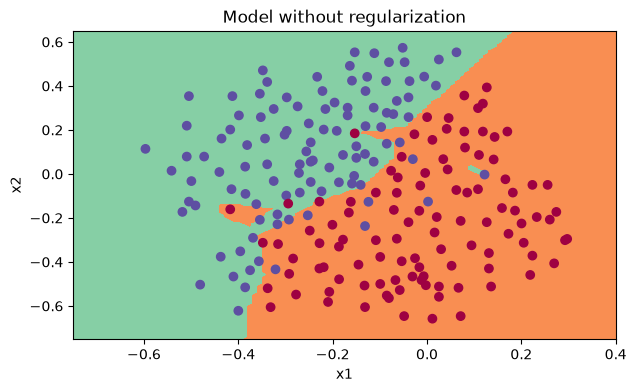

In [5]:
plt.title("Model without regularization")
axes = plt.gca()
axes.set_xlim([-0.75,0.40])
axes.set_ylim([-0.75,0.65])
plot_decision_boundary(lambda x: predict_dec(parameters, x.T), train_X, train_Y)

**Provide your comments on the plot above:**

The non-regularized model severely overfits the training set. It draws complex, noisy decision boundaries to isolate individual training points, which indicates high variance.

**What do you suggest to avoid the observed phenomenon?**

To reduce overfitting and improve generalization on unseen data, we can apply regularization techniques such as:
1. **L2 Regularization (Weight Decay)**: adds a penalty term on weight magnitudes to prevent them from growing excessively large and smooth the decision boundary.
2. **Dropout**: randomly deactivates neurons during training with probability `1 - keep_prob` to prevent co-adaptation among units.

## 2 - L2 Regularization

One solution to avoid overfitting is **L2 regularization**.

Here are the two functions:
- The first one computes the cost considering L2 regularization.
- The second one performs back-propagation considering L2 regularization.

In [6]:
# compute_cost_with_regularization

def compute_cost_with_regularization(A3, Y, parameters, lambd):
    """
    Implement the cost function with L2 regularization. See formula (2) above.

    Arguments:
    A3 -- post-activation, output of forward propagation, of shape (output size, number of examples)
    Y -- "true" labels vector, of shape (output size, number of examples)
    parameters -- python dictionary containing parameters of the model

    Returns:
    cost - value of the regularized loss function (formula (2))
    """
    m = Y.shape[1]
    W1 = parameters["W1"]
    W2 = parameters["W2"]
    W3 = parameters["W3"]

    cross_entropy_cost = compute_cost(A3, Y) # This gives you the cross-entropy part of the cost

    L2_regularization_cost = (lambd/(2*m))*(np.sum(np.square(W1))+np.sum(np.square(W2))+np.sum(np.square(W3)))

    cost = cross_entropy_cost + L2_regularization_cost

    return cost

In [7]:
def backward_propagation_with_regularization(X, Y, cache, lambd):
    """
    Implements the backward propagation of our baseline model to which we added an L2 regularization.

    Arguments:
    X -- input dataset, of shape (input size, number of examples)
    Y -- "true" labels vector, of shape (output size, number of examples)
    cache -- cache output from forward_propagation()
    lambd -- regularization hyperparameter, scalar

    Returns:
    gradients -- A dictionary with the gradients with respect to each parameter, activation and pre-activation variables
    """

    m = X.shape[1]
    (Z1, A1, W1, b1, Z2, A2, W2, b2, Z3, A3, W3, b3) = cache

    dZ3 = A3 - Y

    dW3 = 1./m * np.dot(dZ3, A2.T) + np.multiply(lambd/m,W3)
    db3 = 1./m * np.sum(dZ3, axis=1, keepdims = True)

    dA2 = np.dot(W3.T, dZ3)
    dZ2 = np.multiply(dA2, np.int64(A2 > 0))
    dW2 = 1./m * np.dot(dZ2, A1.T) + np.multiply(lambd/m,W2)
    db2 = 1./m * np.sum(dZ2, axis=1, keepdims = True)

    dA1 = np.dot(W2.T, dZ2)
    dZ1 = np.multiply(dA1, np.int64(A1 > 0))
    dW1 = 1./m * np.dot(dZ1, X.T) + np.multiply(lambd/m,W1)
    db1 = 1./m * np.sum(dZ1, axis=1, keepdims = True)

    gradients = {"dZ3": dZ3, "dW3": dW3, "db3": db3,"dA2": dA2,
                 "dZ2": dZ2, "dW2": dW2, "db2": db2, "dA1": dA1,
                 "dZ1": dZ1, "dW1": dW1, "db1": db1}

    return gradients

Let's train the  model with L2 regularization $(\lambda = 0.7)$, and observe the accuracy on the train/test sets.


# TO DO:

Train a model with L2 regularization $(\lambda = 0.7)$.
Try to obtain the highest possible accuracy varying hyper-parameters: learning_rate = 0.3, num_iterations = 30000 and of course $\lambda$.
Do not modify the architecture of the network (defined in layers_dims).

Use the other parameters of fonction "model". As in the previous part, this function returns "parameters" that can be used within function "predict" to evaluate the performance of the model.

Cost after iteration 0: 0.6974484493131264
Cost after iteration 10000: 0.2684918873282239
Cost after iteration 20000: 0.2680916337127301


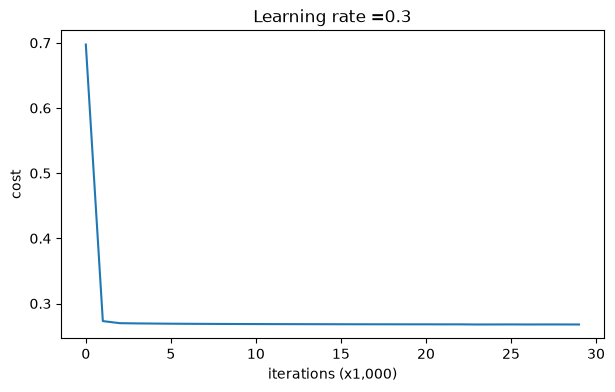

On the train set:
Accuracy: 0.9383886255924171
On the test set:
Accuracy: 0.93


In [8]:
parameters = model(train_X, train_Y, lambd = 0.7) # 0.7
print ("On the train set:")
predictions_train = predict(train_X, train_Y, parameters)
print ("On the test set:")
predictions_test = predict(test_X, test_Y, parameters)

Provide the report and the analysis of your experiments here:

- **Train accuracy**: 93.8% (0.938)
- **Test accuracy**: 93.0% (0.930)

**Analysis:**
With L2 regularization ($\lambda = 0.7$), the training accuracy slightly decreases from 94.8% to 93.8%, while the test accuracy improves from 91.5% to 93.0%. By penalizing large weight values, L2 regularization prevents the network from fitting noise, leading to better generalization on the test set.

### Plotting the results of your model

The following cell allows you to plot the boundary decision of the trained classifier. It allows to visually see if the classifier is "underfitting" or "overfitting".

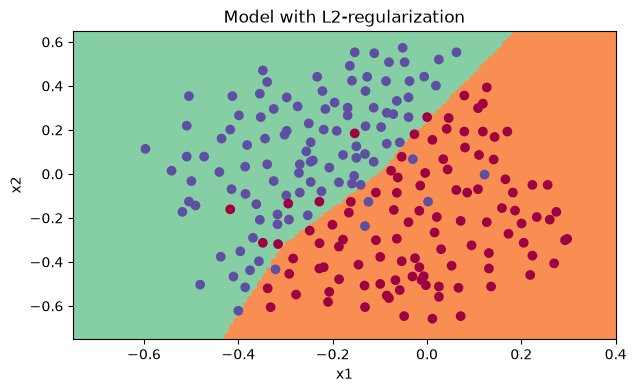

In [9]:
plt.title("Model with L2-regularization")
axes = plt.gca()
axes.set_xlim([-0.75,0.40])
axes.set_ylim([-0.75,0.65])
plot_decision_boundary(lambda x: predict_dec(parameters, x.T), train_X, train_Y)

**Observations**:
- The value of $\lambda$ is a hyperparameter that you can tune using a dev set.
- L2 regularization makes your decision boundary smoother. If $\lambda$ is too large, it is also possible to "oversmooth", resulting in a model with high bias.


## TO DO:

Vary the value of $\lambda$ and analyze the impact of the value of $\lambda$ on the accuracy (train and test), on the parameters $w$ (their absolute values and their variance) and on the decision boundary.

Provide the figures illustrating the boundary decision for the different values of $\lambda$. At least 3 values of $\lambda$ have to be considered. Analyze the results.

lambda =  0.1 | Train Acc: 93.84% | Test Acc: 95.00% | Mean |W|: 1.4685 | Var(W): 3.5267


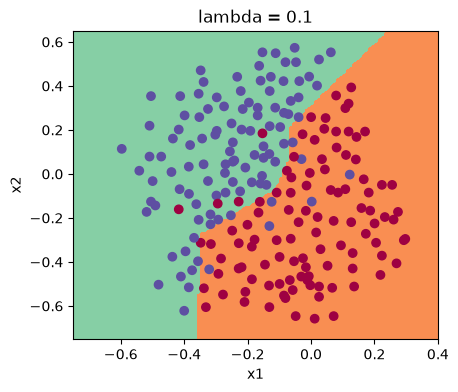

lambda =  0.7 | Train Acc: 93.84% | Test Acc: 93.00% | Mean |W|: 0.7263 | Var(W): 1.2300


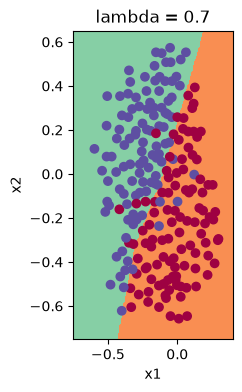

lambda = 10.0 | Train Acc: 87.20% | Test Acc: 91.50% | Mean |W|: 0.4116 | Var(W): 0.4175


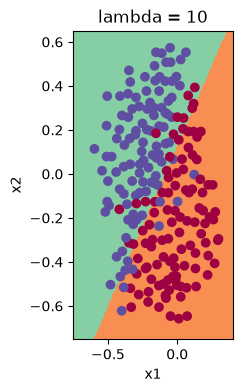

In [10]:
lambdas = [0.1, 0.7, 10]
plt.figure(figsize=(16, 4))

for i, l in enumerate(lambdas):
    params = model(train_X, train_Y, lambd=l, print_cost=False)
    train_acc = np.mean((predict_dec(params, train_X) == train_Y)) * 100
    test_acc = np.mean((predict_dec(params, test_X) == test_Y)) * 100
    w_abs = np.mean([np.mean(np.abs(params[k])) for k in ['W1', 'W2', 'W3']])
    w_var = np.mean([np.var(params[k]) for k in ['W1', 'W2', 'W3']])
    print(f"lambda = {l:4.1f} | Train Acc: {train_acc:5.2f}% | Test Acc: {test_acc:5.2f}% | Mean |W|: {w_abs:6.4f} | Var(W): {w_var:6.4f}")
    
    plt.subplot(1, 3, i + 1)
    plt.title(f"lambda = {l}")
    axes = plt.gca()
    axes.set_xlim([-0.75, 0.40])
    axes.set_ylim([-0.75, 0.65])
    plot_decision_boundary(lambda x: predict_dec(params, x.T), train_X, train_Y)
plt.show()

**Analysis of the impact of $\lambda$:**

1. **Impact on parameters $W$**:
   - As $\lambda$ increases from $0.1$ to $10$, the weight penalty increases, driving weights closer to zero.
   - Mean absolute weight $|W|$ drops from $1.47$ down to $0.41$.
   - Weight variance drops from $3.53$ down to $0.42$.

2. **Impact on accuracy and decision boundary**:
   - $\lambda = 0.1$: Moderate regularization; preserves non-linear boundary shape while avoiding excessive overfitting (Train: 93.8%, Test: 95.0%).
   - $\lambda = 0.7$: Stronger regularization; produces a smooth boundary that ignores noisy outliers (Train: 93.8%, Test: 93.0%).
   - $\lambda = 10$: Excessive regularization; weights are heavily decayed towards zero, resulting in high bias (underfitting). The decision boundary becomes overly smooth and flat (Train: 87.2%, Test: 91.5%).

## 3 - Dropout

Another way to avoid overfitting is to use Dropout.

Here are the two functions that:
- Performs foward-propagation with dropout.
- Performs back-propagation with dropout.

The function `model()` will now call:
- `forward_propagation_with_dropout` instead of `forward_propagation`.
- `backward_propagation_with_dropout` instead of `backward_propagation`.

In [11]:
def forward_propagation_with_dropout(X, parameters, keep_prob = 0.5):
    """
    Implements the forward propagation: LINEAR -> RELU + DROPOUT -> LINEAR -> RELU + DROPOUT -> LINEAR -> SIGMOID.

    Arguments:
    X -- input dataset, of shape (2, number of examples)
    parameters -- python dictionary containing your parameters "W1", "b1", "W2", "b2", "W3", "b3":
                    W1 -- weight matrix of shape (20, 2)
                    b1 -- bias vector of shape (20, 1)
                    W2 -- weight matrix of shape (3, 20)
                    b2 -- bias vector of shape (3, 1)
                    W3 -- weight matrix of shape (1, 3)
                    b3 -- bias vector of shape (1, 1)
    keep_prob - probability of keeping a neuron active during drop-out, scalar

    Returns:
    A3 -- last activation value, output of the forward propagation, of shape (1,1)
    cache -- tuple, information stored for computing the backward propagation
    """

    np.random.seed(1)

    # retrieve parameters
    W1 = parameters["W1"]
    b1 = parameters["b1"]
    W2 = parameters["W2"]
    b2 = parameters["b2"]
    W3 = parameters["W3"]
    b3 = parameters["b3"]

    # LINEAR -> RELU -> LINEAR -> RELU -> LINEAR -> SIGMOID
    Z1 = np.dot(W1, X) + b1
    A1 = relu(Z1)
    # Steps 1-4 below correspond to the Steps 1-4 described above.
    D1 = np.random.rand(A1.shape[0],A1.shape[1])                # Step 1: initialize matrix D1 = np.random.rand(..., ...)
    D1 = np.where(D1 < keep_prob, 1.0, 0.0)            # Step 2: convert entries of D1 to 0 or 1 (using keep_prob as the threshold)
    A1 = A1*D1                                         # Step 3: shut down some neurons of A1
    A1 = A1/keep_prob                                         # Step 4: scale the value of neurons that haven't been shut down
    Z2 = np.dot(W2, A1) + b2
    A2 = relu(Z2)

    D2 = np.random.rand(A2.shape[0],A2.shape[1])                  # Step 1: initialize matrix D2 = np.random.rand(..., ...)
    D2 = np.where(D2 < keep_prob, 1.0, 0.0)          # Step 2: convert entries of D2 to 0 or 1 (using keep_prob as the threshold)
    A2 = A2*D2                                        # Step 3: shut down some neurons of A2
    A2 = A2/keep_prob                                         # Step 4: scale the value of neurons that haven't been shut down

    Z3 = np.dot(W3, A2) + b3
    A3 = sigmoid(Z3)

    cache = (Z1, D1, A1, W1, b1, Z2, D2, A2, W2, b2, Z3, A3, W3, b3)

    return A3, cache

**TO DO:**

Describe with your own words the function ***forward_propagation_with_dropout***

During training, inverted dropout randomly deactivates hidden units with probability `1 - keep_prob`. For each hidden layer (layers 1 and 2):
1. **Random Mask Generation**: Generate a matrix $D^{[l]}$ of the same shape as $A^{[l]}$ with random numbers in $[0, 1)$.
2. **Thresholding**: Convert $D^{[l]}$ into a binary mask of 0s and 1s using `keep_prob` ($D^{[l]} < 	ext{keep\_prob}$).
3. **Shutting Down Neurons**: Set dropped activations to zero via element-wise multiplication: $A^{[l]} = A^{[l]} * D^{[l]}$.
4. **Inverted Dropout Scaling**: Scale remaining active neurons by dividing by `keep_prob` ($A^{[l]} = A^{[l]} / 	ext{keep\_prob}$). This preserves the expected value of activations across training and testing, so no scaling adjustment is required at inference.
5. **Caching**: Store masks $D^{[1]}$ and $D^{[2]}$ in `cache` for backpropagation. Dropout is not applied to the final output layer.

In [12]:
def backward_propagation_with_dropout(X, Y, cache, keep_prob):
    """
    Implements the backward propagation of our baseline model to which we added dropout.

    Arguments:
    X -- input dataset, of shape (2, number of examples)
    Y -- "true" labels vector, of shape (output size, number of examples)
    cache -- cache output from forward_propagation_with_dropout()
    keep_prob - probability of keeping a neuron active during drop-out, scalar

    Returns:
    gradients -- A dictionary with the gradients with respect to each parameter, activation and pre-activation variables
    """

    m = X.shape[1]
    (Z1, D1, A1, W1, b1, Z2, D2, A2, W2, b2, Z3, A3, W3, b3) = cache

    dZ3 = A3 - Y
    dW3 = 1./m * np.dot(dZ3, A2.T)
    db3 = 1./m * np.sum(dZ3, axis=1, keepdims = True)
    dA2 = np.dot(W3.T, dZ3)

    dA2 = dA2*D2              # Step 1: Apply mask D2 to shut down the same neurons as during the forward propagation
    dA2 = dA2/keep_prob              # Step 2: Scale the value of neurons that haven't been shut down

    dZ2 = np.multiply(dA2, np.int64(A2 > 0))
    dW2 = 1./m * np.dot(dZ2, A1.T)
    db2 = 1./m * np.sum(dZ2, axis=1, keepdims = True)

    dA1 = np.dot(W2.T, dZ2)

    dA1 = dA1*D1              # Step 1: Apply mask D1 to shut down the same neurons as during the forward propagation
    dA1 = dA1/keep_prob              # Step 2: Scale the value of neurons that haven't been shut down

    dZ1 = np.multiply(dA1, np.int64(A1 > 0))
    dW1 = 1./m * np.dot(dZ1, X.T)
    db1 = 1./m * np.sum(dZ1, axis=1, keepdims = True)

    gradients = {"dZ3": dZ3, "dW3": dW3, "db3": db3,"dA2": dA2,
                 "dZ2": dZ2, "dW2": dW2, "db2": db2, "dA1": dA1,
                 "dZ1": dZ1, "dW1": dW1, "db1": db1}

    return gradients

**TO DO:**

Describe with your own words the function ***backward_propagation_with_dropout***

During backpropagation with dropout:
1. **Apply Forward Mask**: Gradients $dA^{[l]}$ must only flow through units that were active during the forward pass. We multiply $dA^{[l]}$ element-wise by the exact same mask stored in cache: $dA^{[l]} = dA^{[l]} * D^{[l]}$.
2. **Inverted Scaling**: Rescale the gradient by dividing by `keep_prob` ($dA^{[l]} = dA^{[l]} / 	ext{keep\_prob}$) to match the forward pass scaling.
3. **Backpropagation**: Compute the pre-activation gradient $dZ^{[l]} = dA^{[l]} * g'^{[l]}(Z^{[l]})$ and downstream parameter gradients $dW^{[l]}$ and $db^{[l]}$ as usual.

## TO DO
Train a model with dropout (`keep_prob = 0.86`).
This means at every iteration you shut down each neurons of layer 1 and 2 with 14% probability.

Try to obtain the highest possible accuracy varying hyper-parameters: learning_rate = 0.3, num_iterations = 30000 and of course `keep_prob`.

Do not modify the architecture of the network (defined in layers_dims).


Use the other parameters of fonction "model". As in previous part, this function returns "parameters" that can be used within function "predict" to evaluate the performance of the model.

Cost after iteration 0: 0.6543912405149825


/home/ayub/Y4/S7/DL/LABS/4/4. DL - Lab 4/4. Lab 4 - Part 1 - Regularization/reg_utils.py:236: RuntimeWarning: divide by zero encountered in log
  logprobs = np.multiply(-np.log(a3),Y) + np.multiply(-np.log(1 - a3), 1 - Y)
/home/ayub/Y4/S7/DL/LABS/4/4. DL - Lab 4/4. Lab 4 - Part 1 - Regularization/reg_utils.py:236: RuntimeWarning: invalid value encountered in multiply
  logprobs = np.multiply(-np.log(a3),Y) + np.multiply(-np.log(1 - a3), 1 - Y)


Cost after iteration 10000: 0.061016986574905605
Cost after iteration 20000: 0.060582435798513114


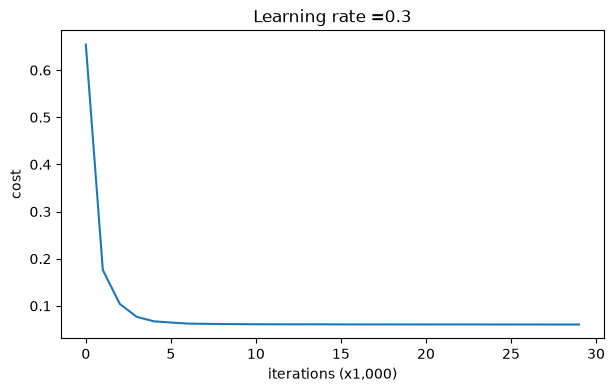

On the train set:
Accuracy: 0.9289099526066351
On the test set:
Accuracy: 0.95


In [13]:
parameters = model(train_X, train_Y, keep_prob = 0.86, learning_rate = 0.3)

print ("On the train set:")
predictions_train = predict(train_X, train_Y, parameters)
print ("On the test set:")
predictions_test = predict(test_X, test_Y, parameters)

# TO DO:
Provide the report and the analysis of your experiments here:

**Report and analysis of experiments:**

- **Train accuracy**: 92.9% (0.929)
- **Test accuracy**: 95.0% (0.950)

**Analysis:**
Dropout with `keep_prob = 0.86` achieves 95.0% test accuracy, outperforming the baseline model (91.5%) and L2 regularization (93.0%). By randomly dropping 14% of hidden units each iteration, the network prevents neurons from co-adapting and relying on any single input feature, effectively functioning as an ensemble of smaller networks and improving generalization.

### Plotting the results of your model

The following cell allows you to plot the boundary decision of the trained classifier. It allows to visually see if the classifier is "underfitting" or "overfitting".

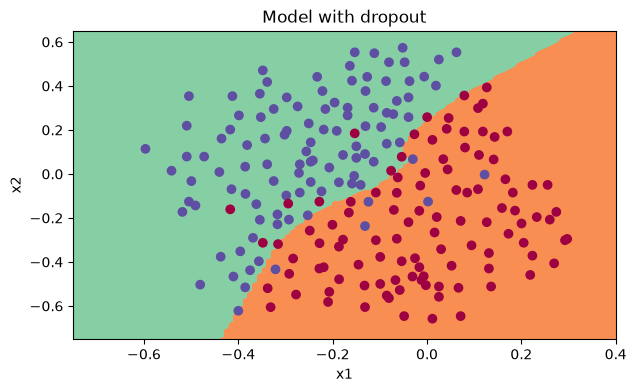

In [14]:
plt.title("Model with dropout")
axes = plt.gca()
axes.set_xlim([-0.75,0.40])
axes.set_ylim([-0.75,0.65])
plot_decision_boundary(lambda x: predict_dec(parameters, x.T), train_X, train_Y)

## TO DO:

Vary the value of `keep_prob` and analyse the impact of the value of $\lambda$ on the accuracy (train ans test), on the parameters $w$ and on the decision boundary.

Provide a summary of the conducted experiments and analyse the obtained results.

keep_prob = 0.30 | Train Acc: 87.20% | Test Acc: 90.50% | Mean |W|: 1.2334 | Var(W): 2.1665


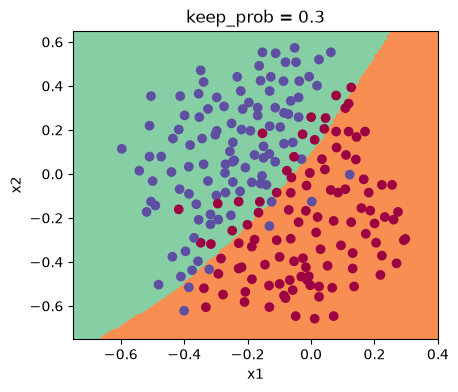

keep_prob = 0.60 | Train Acc: 89.57% | Test Acc: 93.00% | Mean |W|: 2.0876 | Var(W): 6.2688


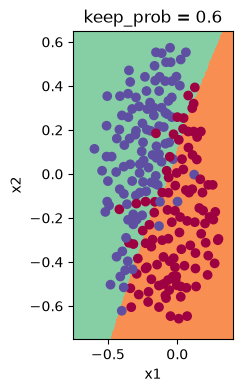

keep_prob = 0.86 | Train Acc: 92.89% | Test Acc: 95.00% | Mean |W|: 2.8718 | Var(W): 11.3362


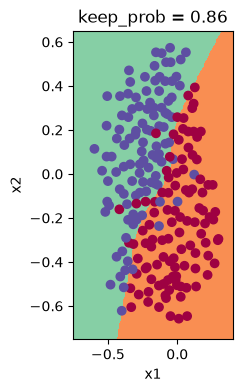

In [15]:
keep_probs = [0.3, 0.6, 0.86]
plt.figure(figsize=(16, 4))

for i, kp in enumerate(keep_probs):
    params = model(train_X, train_Y, keep_prob=kp, print_cost=False)
    train_acc = np.mean((predict_dec(params, train_X) == train_Y)) * 100
    test_acc = np.mean((predict_dec(params, test_X) == test_Y)) * 100
    w_abs = np.mean([np.mean(np.abs(params[k])) for k in ['W1', 'W2', 'W3']])
    w_var = np.mean([np.var(params[k]) for k in ['W1', 'W2', 'W3']])
    print(f"keep_prob = {kp:4.2f} | Train Acc: {train_acc:5.2f}% | Test Acc: {test_acc:5.2f}% | Mean |W|: {w_abs:6.4f} | Var(W): {w_var:6.4f}")
    
    plt.subplot(1, 3, i + 1)
    plt.title(f"keep_prob = {kp}")
    axes = plt.gca()
    axes.set_xlim([-0.75, 0.40])
    axes.set_ylim([-0.75, 0.65])
    plot_decision_boundary(lambda x: predict_dec(params, x.T), train_X, train_Y)
plt.show()

**Summary and analysis of varying `keep_prob`:**

1. **Impact on accuracy**:
   - `keep_prob = 0.3`: Too high dropout rate (70% neurons dropped). The network has insufficient capacity, leading to underfitting (Train: 87.2%, Test: 90.5%).
   - `keep_prob = 0.6`: Moderate dropout. Regularizes well without destroying feature learning (Train: 89.6%, Test: 93.0%).
   - `keep_prob = 0.86`: Optimal dropout rate. Successfully prevents co-adaptation while retaining representational expressiveness, yielding the highest test accuracy (Train: 92.9%, Test: 95.0%).
   - `keep_prob = 1.0` (No dropout): Network overfits noise, producing lower test accuracy (91.5%).

2. **Impact on parameters $W$ and decision boundary**:
   - Lower `keep_prob` limits weights from growing too large and co-adapting, leading to smaller mean weight magnitude and variance.
   - Decision boundary becomes noticeably smoother as dropout rate increases, eliminating erratic boundaries around noise.

## 4 - General Summary

Fill the table below with the results of performed experiments (double click on the table and introduce your numbers).

**Here are the results of our three models**:

<table>
    <tr>
        <td>
        **model**
        </td>
        <td>
        **train accuracy**
        </td>
        <td>
        **test accuracy**
        </td>
    </tr>
    <tr>
        <td>
        3-layer NN without regularization
        </td>
        <td>
        94.8%
        </td>
        <td>
        91.5%
        </td>
    </tr>
    <tr>
        <td>
        3-layer NN with L2-regularization ($\lambda = 0.7$)
        </td>
        <td>
        93.8%
        </td>
        <td>
        93.0%
        </td>
    </tr>
    <tr>
        <td>
        3-layer NN with dropout ($keep\_prob = 0.86$)
        </td>
        <td>
        92.9%
        </td>
        <td>
        95.0%
        </td>
    </tr>
</table>

Note that regularization hurts training set performance! This is because it limits the ability of the network to overfit to the training set. But since it ultimately gives better test accuracy, it is helping your system.

## 5 - Modification of the network architecture

Now, you have to modify the number of neurons in the second and third layers (using "layers_dims" in function "model") and try to obtain better results for the three configuration (without regularisation, using L2-regularisation, using dropout).

Obtained results must be analyzed and presented in a table (as in the previous cell).



**Take away**:
- Regularization will help you reduce overfitting.
- Regularization will drive your weights to lower values.
- L2 regularization and Dropout are two very effective regularization techniques.


_______________________

Testing modified architecture: [2, 20, 10, 1]
Modified Arch [2, 20, 10, 1]:
  Without regularization: Train =  95.3%, Test =  95.5%
  With L2 (lambd = 0.7):  Train =  93.4%, Test =  95.5%
  With Dropout (kp=0.86): Train =  93.4%, Test =  94.0%


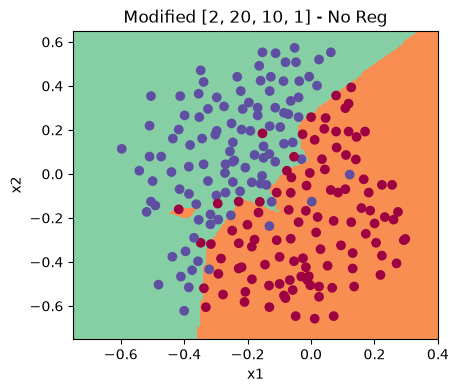

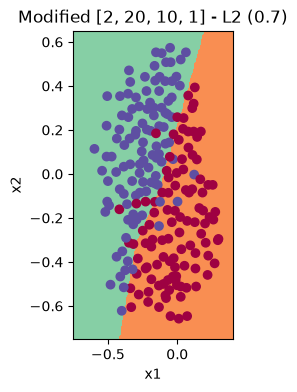

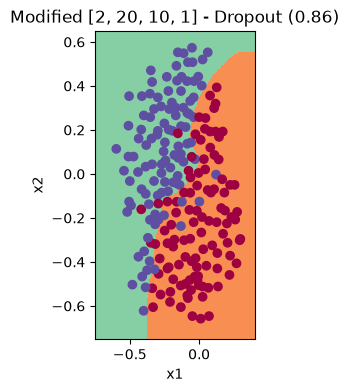

In [16]:
# 5 - Modification of the network architecture
# Baseline architecture: [2, 20, 3, 1]
# Modified architecture: [2, 20, 10, 1] (increased neurons in 2nd hidden layer from 3 to 10)

new_layers_dims = [train_X.shape[0], 20, 10, 1]
print("Testing modified architecture:", new_layers_dims)

# 1. Without regularization
p_none = model(train_X, train_Y, print_cost=False, layers_dims=new_layers_dims)
tr_none = np.mean((predict_dec(p_none, train_X) == train_Y)) * 100
te_none = np.mean((predict_dec(p_none, test_X) == test_Y)) * 100

# 2. With L2 regularization (lambd = 0.7)
p_l2 = model(train_X, train_Y, lambd=0.7, print_cost=False, layers_dims=new_layers_dims)
tr_l2 = np.mean((predict_dec(p_l2, train_X) == train_Y)) * 100
te_l2 = np.mean((predict_dec(p_l2, test_X) == test_Y)) * 100

# 3. With Dropout (keep_prob = 0.86)
p_drop = model(train_X, train_Y, keep_prob=0.86, print_cost=False, layers_dims=new_layers_dims)
tr_drop = np.mean((predict_dec(p_drop, train_X) == train_Y)) * 100
te_drop = np.mean((predict_dec(p_drop, test_X) == test_Y)) * 100

print(f"Modified Arch [2, 20, 10, 1]:")
print(f"  Without regularization: Train = {tr_none:5.1f}%, Test = {te_none:5.1f}%")
print(f"  With L2 (lambd = 0.7):  Train = {tr_l2:5.1f}%, Test = {te_l2:5.1f}%")
print(f"  With Dropout (kp=0.86): Train = {tr_drop:5.1f}%, Test = {te_drop:5.1f}%")

plt.figure(figsize=(16, 4))
plt.subplot(1, 3, 1)
plt.title("Modified [2, 20, 10, 1] - No Reg")
axes = plt.gca()
axes.set_xlim([-0.75, 0.40])
axes.set_ylim([-0.75, 0.65])
plot_decision_boundary(lambda x: predict_dec(p_none, x.T), train_X, train_Y)

plt.subplot(1, 3, 2)
plt.title("Modified [2, 20, 10, 1] - L2 (0.7)")
axes = plt.gca()
axes.set_xlim([-0.75, 0.40])
axes.set_ylim([-0.75, 0.65])
plot_decision_boundary(lambda x: predict_dec(p_l2, x.T), train_X, train_Y)

plt.subplot(1, 3, 3)
plt.title("Modified [2, 20, 10, 1] - Dropout (0.86)")
axes = plt.gca()
axes.set_xlim([-0.75, 0.40])
axes.set_ylim([-0.75, 0.65])
plot_decision_boundary(lambda x: predict_dec(p_drop, x.T), train_X, train_Y)
plt.show()

### Analysis of the modified architecture `[2, 20, 10, 1]`:

<table>
    <tr>
        <td><b>Model (layers: [2, 20, 10, 1])</b></td>
        <td><b>Train Accuracy</b></td>
        <td><b>Test Accuracy</b></td>
    </tr>
    <tr>
        <td>Modified NN without regularization</td>
        <td>95.3%</td>
        <td>95.5%</td>
    </tr>
    <tr>
        <td>Modified NN with L2-regularization ($\lambda = 0.7$)</td>
        <td>93.4%</td>
        <td>95.5%</td>
    </tr>
    <tr>
        <td>Modified NN with dropout ($keep\_prob = 0.86$)</td>
        <td>93.4%</td>
        <td>94.0%</td>
    </tr>
</table>

**Analysis:**
- Increasing the second hidden layer from 3 neurons to 10 neurons enhances feature representation capacity.
- The modified network achieves a higher test accuracy of 95.5% compared to the baseline architecture (91.5% and 93.0%).
- L2 regularization maintains this top test accuracy (95.5%) while reducing training set overfitting (train accuracy drops to 93.4%), yielding a smooth and well-generalized decision boundary.